# Proyecto Final · Análisis, estadísticas y visualizaciones (2/2)
## Abandono escolar en México (ENAPE 2021)

**Pregunta 12:** ¿Qué factores socioeconómicos (ingreso del hogar, escolaridad de los padres, zona) se asocian con el abandono escolar, y cuáles son las razones más frecuentes reportadas por sexo del estudiante?

**Hipótesis inicial:** (H1) el abandono es mayor en hogares de menor nivel socioeconómico; (H2) se concentra en la transición a media superior; (H3) los hombres abandonan más por razones laborales y las mujeres por unión/embarazo y cuidados.

**Insumo:** `datos_limpios/enape2021_abandono_limpia.csv`, generado por `limpieza_1.ipynb`.

**Nota metodológica:** todas las cifras son **ponderadas con el factor de expansión** (representan a la población, no a la muestra). Los intervalos de confianza al 95 % usan el tamaño de muestra efectivo de Kish, $n_{ef} = (\sum w)^2 / \sum w^2$; como la base pública no trae estratos ni conglomerados, son una aproximación.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

d = pd.read_csv("datos_limpios/enape2021_abandono_limpia.csv", dtype={"folio": str, "renglon": str})
GRAF = Path("graficas"); GRAF.mkdir(exist_ok=True)

# ---- Estilo gráfico (paleta validada para daltonismo: azul/naranja; rampa secuencial azul) ----
C = {"Hombre": "#2a78d6", "Mujer": "#eb6834", "tinta": "#0b0b0b", "tinta2": "#52514e",
     "grid": "#e4e3df", "fondo": "#fcfcfb", "neutro": "#b8b7b1"}
AZUL = {"Bajo (0-2 bienes)": "#86b6ef", "Medio (3-4)": "#2a78d6", "Alto (5-6)": "#104281"}
NSE_ORD = ["Bajo (0-2 bienes)", "Medio (3-4)", "Alto (5-6)"]
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "savefig.facecolor": C["fondo"],
    "font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": C["grid"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tinta2"], "ytick.color": C["tinta2"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"],
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlecolor": C["tinta"], "axes.titlelocation": "left", "legend.frameon": False})

def guardar(fig, nombre, fuente=True):
    if fuente:
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        fig.text(bb.x0 / fig.get_figwidth(), bb.y0 / fig.get_figheight() - 0.045, "Fuente: elaboración propia con datos de INEGI, ENAPE 2021. Cifras ponderadas.",
                 fontsize=8.5, color=C["tinta2"], ha="left")
    fig.savefig(GRAF / f"{nombre}.png", dpi=170, bbox_inches="tight")

# ---- Funciones ponderadas ----
def tasa(s, y="abandono_reciente"):
    s = s[s[y].notna()]
    w, x = s["factor"], s[y]
    p = np.average(x, weights=w)
    n_ef = w.sum() ** 2 / (w ** 2).sum()
    ee = np.sqrt(p * (1 - p) / n_ef)
    return pd.Series({"tasa_%": p * 100, "ic_inf": max(0, p - 1.96 * ee) * 100, "ic_sup": (p + 1.96 * ee) * 100,
                      "casos_muestra": len(s), "poblacion_millones": w.sum() / 1e6,
                      "abandonos_millones": w[x == 1].sum() / 1e6})

def tabla(grupo, y="abandono_reciente", data=None):
    data = d if data is None else data
    return data[data[y].notna()].groupby(grupo, observed=True).apply(lambda s: tasa(s, y)).round(2)

def wmedia(x, w): return np.average(x, weights=w)
def wsd(x, w): return np.sqrt(np.average((x - wmedia(x, w)) ** 2, weights=w))
def wmediana(x, w):
    o = np.argsort(x.values); xs, ws = x.values[o], w.values[o]
    return xs[np.searchsorted(np.cumsum(ws), ws.sum() / 2)]

ab = d[d["abandono_reciente"].notna()].copy()   # población en riesgo: 6-29 años inscritos en 2020-21
print(f"Población en riesgo: {len(ab):,} casos en muestra = {ab.factor.sum()/1e6:.1f} millones de personas")

Población en riesgo: 18,207 casos en muestra = 29.9 millones de personas


## 1. Estadísticos descriptivos y respuesta directa

### 1.1 ¿Cuánto abandono hubo?

In [2]:
total = tasa(ab)
print(f"Tasa de abandono escolar 2020-21 → 2021-22: {total['tasa_%']:.1f} % "
      f"(IC 95 %: {total.ic_inf:.1f}–{total.ic_sup:.1f})")
print(f"Personas de 6-29 años que dejaron la escuela: {total.abandonos_millones:.2f} millones")
tabla("sexo")

Tasa de abandono escolar 2020-21 → 2021-22: 7.1 % (IC 95 %: 6.5–7.7)
Personas de 6-29 años que dejaron la escuela: 2.12 millones


,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
sexo,,,,,,
Hombre,7.24,6.44,8.05,9329.0,14.89,1.08
Mujer,6.94,6.09,7.79,8878.0,15.05,1.04


### 1.2 Descriptivos de las variables numéricas (ponderados), según si abandonó o continuó

In [3]:
num = {"edad": "Edad (años)", "indice_tic": "Índice TIC del hogar (0-6)", "tam_hogar": "Tamaño del hogar (personas)",
       "tic_internet": "Hogar con internet fijo (proporción)", "sin_internet_por_dinero": "Sin internet por falta de dinero (proporción)"}
filas = []
for v, et in num.items():
    for g, s in [("Total", ab), ("Continuó", ab[ab.abandono_reciente == 0]), ("Abandonó", ab[ab.abandono_reciente == 1])]:
        x, w = s[v].astype(float), s["factor"]
        filas.append({"variable": et, "grupo": g, "media": wmedia(x, w), "mediana": wmediana(x, w),
                      "desv_est": wsd(x, w), "min": x.min(), "max": x.max()})
desc = pd.DataFrame(filas).pivot_table(index="variable", columns="grupo", values=["media", "mediana", "desv_est"],
                                        sort=False).round(2)
desc

media           ... desv_est         
grupo                                          Total Continuó  ... Continuó Abandonó
variable                                                       ...                  
Edad (años)                                    13.32    13.03  ...     4.96     3.78
Índice TIC del hogar (0-6)                      3.34     3.38  ...     1.44     1.41
Tamaño del hogar (personas)                     5.58     5.55  ...     2.48     2.87
Hogar con internet fijo (proporción)            0.72     0.73  ...     0.44     0.49
Sin internet por falta de dinero (proporción)   0.22     0.21  ...     0.41     0.47

[5 rows x 9 columns]

### 1.3 Correlaciones ponderadas con el abandono
Correlación de Pearson ponderada (con una variable binaria equivale a la correlación punto-biserial).

In [4]:
def wcorr(a, b, w):
    ma, mb = wmedia(a, w), wmedia(b, w)
    return np.average((a - ma) * (b - mb), weights=w) / (wsd(a, w) * wsd(b, w))

ab["mujer"] = (ab.sexo == "Mujer").astype(int)
ab["informante_es_padre"] = (ab.informante_padre_madre == "Madre/padre").astype(int)
vc = ["abandono_reciente", "indice_tic", "edad", "tam_hogar", "tic_internet", "sin_internet_por_dinero",
      "sin_cobertura_internet", "informante_es_padre", "mujer"]
corr = pd.DataFrame([[wcorr(ab[a].astype(float), ab[b].astype(float), ab.factor) for b in vc] for a in vc],
                    index=vc, columns=vc).round(3)
corr[["abandono_reciente"]].drop("abandono_reciente").sort_values("abandono_reciente")

,abandono_reciente
indice_tic,-0.096
tic_internet,-0.094
informante_es_padre,-0.084
mujer,-0.006
sin_cobertura_internet,0.019
tam_hogar,0.039
sin_internet_por_dinero,0.077
edad,0.210


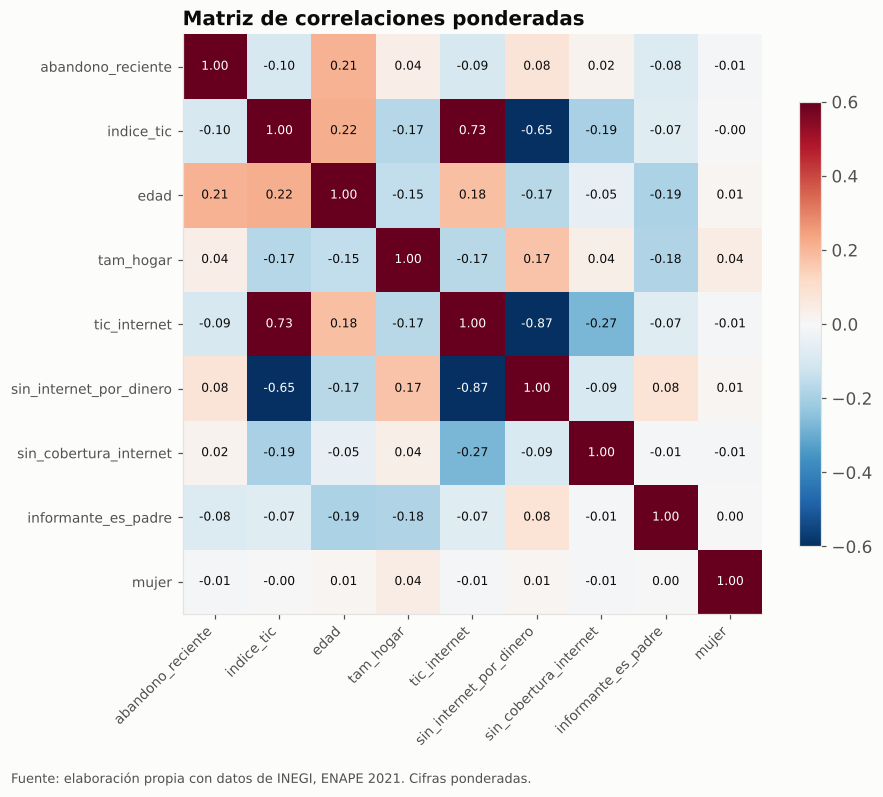

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
ax.set_xticks(range(len(vc)), vc, rotation=45, ha="right", fontsize=9); ax.set_yticks(range(len(vc)), vc, fontsize=9)
ax.grid(False)
for i in range(len(vc)):
    for j in range(len(vc)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.values[i, j]) > 0.4 else C["tinta"])
fig.colorbar(im, ax=ax, shrink=0.75)
ax.set_title("Matriz de correlaciones ponderadas")
guardar(fig, "00_matriz_correlaciones")

**Lectura:** el abandono se correlaciona negativamente con el equipamiento del hogar (índice TIC) y con tener internet, y positivamente con no tener internet por falta de dinero. Las correlaciones son modestas porque el abandono es un evento poco frecuente (7 %); por eso se complementan con tasas por grupo y un modelo multivariado (sección 7).

## 2. Factor 1 · Ingreso del hogar (proxy: equipamiento TIC)

,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
nse_tic,,,,,,
Bajo (0-2 bienes),10.39,8.94,11.85,4932.0,8.98,0.93
Medio (3-4),6.57,5.80,7.35,8821.0,14.16,0.93
Alto (5-6),3.80,2.96,4.64,4454.0,6.80,0.26


,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
indice_tic,,,,,,
0,12.13,6.05,18.20,210.0,0.37,0.04
1,11.71,9.42,14.00,1735.0,3.27,0.38
2,9.47,7.54,11.40,2987.0,5.35,0.51
3,6.85,5.65,8.04,3820.0,6.40,0.44
4,6.35,5.33,7.37,5001.0,7.76,0.49
5,4.08,3.07,5.09,3185.0,4.87,0.20
6,3.11,1.63,4.58,1269.0,1.94,0.06


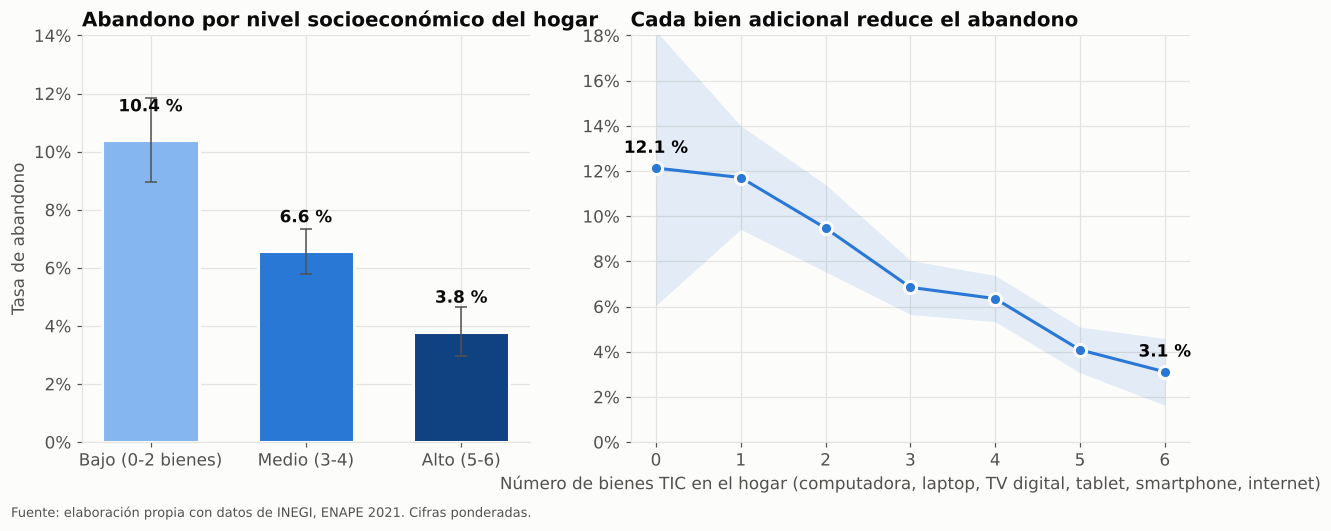

In [6]:
t_nse = tabla("nse_tic").reindex(NSE_ORD)
t_tic = tabla("indice_tic")
display(t_nse, t_tic)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
b = a1.bar(range(3), t_nse["tasa_%"], color=[AZUL[k] for k in NSE_ORD], width=0.62, edgecolor=C["fondo"], linewidth=2)
a1.errorbar(range(3), t_nse["tasa_%"], yerr=[t_nse["tasa_%"] - t_nse.ic_inf, t_nse.ic_sup - t_nse["tasa_%"]],
            fmt="none", ecolor=C["tinta2"], capsize=4, lw=1)
for i, v in enumerate(t_nse["tasa_%"]):
    a1.text(i, v + 1.0, f"{v:.1f} %", ha="center", fontweight="bold", color=C["tinta"])
a1.set_xticks(range(3), NSE_ORD); a1.set_ylim(0, 14); a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a1.set_title("Abandono por nivel socioeconómico del hogar"); a1.set_ylabel("Tasa de abandono")
a2.plot(t_tic.index, t_tic["tasa_%"], color=C["Hombre"], lw=2, marker="o", ms=8, markeredgecolor=C["fondo"], mew=2)
a2.fill_between(t_tic.index, t_tic.ic_inf, t_tic.ic_sup, color=C["Hombre"], alpha=0.12, lw=0)
for x, v in [(0, t_tic.loc[0, "tasa_%"]), (6, t_tic.loc[6, "tasa_%"])]:
    a2.annotate(f"{v:.1f} %", (x, v), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
a2.set_xticks(range(7)); a2.set_xlabel("Número de bienes TIC en el hogar (computadora, laptop, TV digital, tablet, smartphone, internet)")
a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a2.set_ylim(0, 18)
a2.set_title("Cada bien adicional reduce el abandono")
guardar(fig, "01_abandono_nse")

**Hallazgo:** gradiente monótono y fuerte. En hogares con nivel socioeconómico **bajo** el abandono es **10.4 %**, casi **3 veces** el de hogares de nivel **alto** (3.8 %). Se confirma H1. La relación es escalonada: de 12 % sin bienes a 3 % con los seis.

## 3. Patrón por etapa escolar: la desigualdad se multiplica en la transición

,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
nivel_agrupado_2020_21,,,,,,
Primaria,2.05,1.53,2.56,7172.0,12.99,0.27
Secundaria,8.45,7.07,9.83,3694.0,6.07,0.51
Media superior,19.17,17.10,21.24,3461.0,5.06,0.97
Superior,8.92,7.32,10.51,2926.0,4.02,0.36


nse_tic,Bajo (0-2 bienes),Medio (3-4),Alto (5-6)
nivel_agrupado_2020_21,,,
Primaria,3.8,1.4,0.1
Secundaria,15.4,6.7,1.6
Media superior,33.8,16.7,12.0
Superior,16.1,10.5,4.9


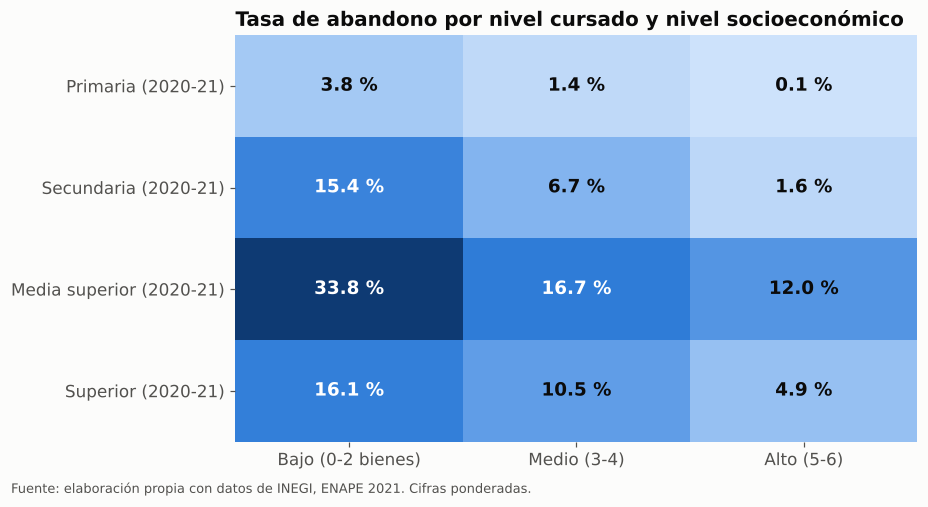

In [7]:
niveles = ["Primaria", "Secundaria", "Media superior", "Superior"]
heat = ab[ab.nivel_agrupado_2020_21.isin(niveles)].groupby(["nivel_agrupado_2020_21", "nse_tic"], observed=True) \
    .apply(lambda s: tasa(s)["tasa_%"]).unstack().reindex(index=niveles, columns=NSE_ORD)
display(tabla("nivel_agrupado_2020_21").reindex(niveles), heat.round(1))

fig, ax = plt.subplots(figsize=(8, 4.8))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
ax.imshow(heat.values, cmap=cmap, aspect="auto", vmin=0, vmax=35)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1f} %", ha="center", va="center", fontsize=12, fontweight="bold",
                color="white" if v > 12 else C["tinta"])
ax.set_xticks(range(3), NSE_ORD); ax.set_yticks(range(4), [f"{n} (2020-21)" for n in niveles])
ax.set_title("Tasa de abandono por nivel cursado y nivel socioeconómico")
for s in ax.spines.values(): s.set_visible(False)
guardar(fig, "02_heatmap_nivel_nse")

**Hallazgo (patrón no evidente):** el riesgo se dispara en **media superior** (19 % en promedio) y ahí la brecha socioeconómica es máxima: **1 de cada 3** estudiantes de bachillerato de hogares de nivel bajo no volvió (33.8 %), contra 12 % en hogares de nivel alto. En primaria la diferencia es de 3.8 % vs 0.1 %. Se confirma H2: la desigualdad se acumula en las transiciones.

## 4. Patrón por edad y sexo

tasa_%  ...  abandonos_millones
grupo_edad         sexo            ...                    
12-14 (secundaria) Hombre    3.55  ...                0.11
                   Mujer     3.49  ...                0.11
15-17 (media sup.) Hombre   13.84  ...                0.36
                   Mujer    11.16  ...                0.28
18-22 (superior)   Hombre   19.39  ...                0.45
                   Mujer    19.57  ...                0.54
23-29              Hombre   11.58  ...                0.08
                   Mujer     9.26  ...                0.06
6-11 (primaria)    Hombre    1.26  ...                0.08
                   Mujer     0.94  ...                0.06

[10 rows x 6 columns]

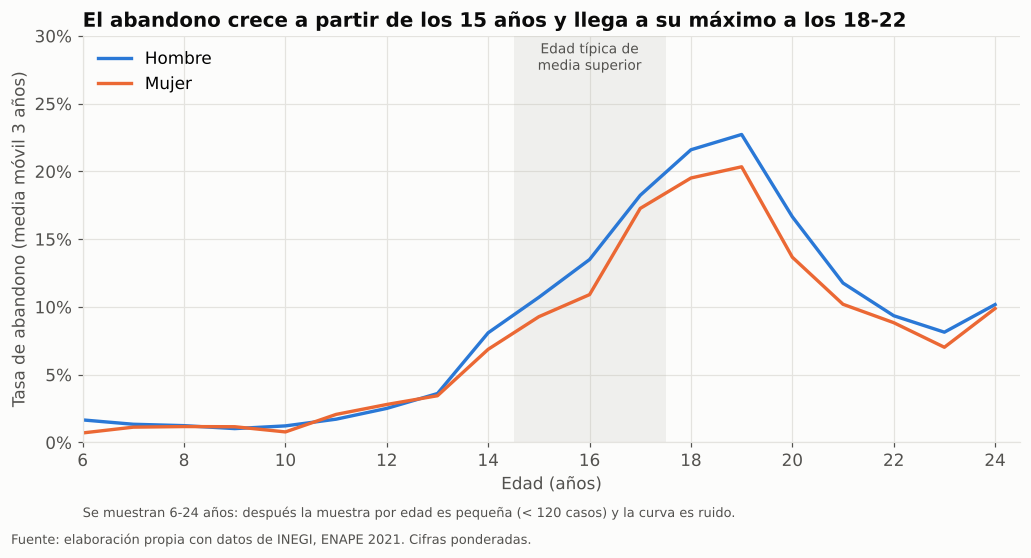

In [8]:
edad_sexo = ab.groupby(["edad", "sexo"]).apply(lambda s: tasa(s)["tasa_%"]).unstack()
display(tabla(["grupo_edad", "sexo"]))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axvspan(14.5, 17.5, color=C["neutro"], alpha=0.18, lw=0)
ax.text(16, 27.5, "Edad típica de\nmedia superior", ha="center", fontsize=9, color=C["tinta2"])
for s in ["Hombre", "Mujer"]:
    y = edad_sexo[s].rolling(3, center=True, min_periods=1).mean().loc[6:24]
    ax.plot(y.index, y.values, color=C[s], lw=2.2, label=s)
ax.set_xticks(range(6, 25, 2))
ax.set_xlim(6, 24.5); ax.set_ylim(0, 30); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Edad (años)"); ax.set_ylabel("Tasa de abandono (media móvil 3 años)")
ax.set_title("El abandono crece a partir de los 15 años y llega a su máximo a los 18-22")
ax.text(6, -5.5, "Se muestran 6-24 años: después la muestra por edad es pequeña (< 120 casos) y la curva es ruido.", fontsize=8.5, color=C["tinta2"])
ax.legend(loc="upper left")
guardar(fig, "03_abandono_edad_sexo")

**Hallazgo:** casi no hay abandono en primaria (1 %) pero a los 15-17 años sube a 12.5 % y a los 18-22 a 19.5 %. Los hombres abandonan más en media superior (13.8 % vs 11.2 %), la etapa en que entran al mercado laboral.

## 5. Factor 2 · Zona y territorio
La ENAPE no identifica localidades urbanas/rurales; se usan región, entidad y hogares sin internet porque *no hay servicio en la zona* (señal de localidad remota).

,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
region,,,,,,
Centro,6.61,5.47,7.74,4220.0,9.20,0.61
Norte,7.02,6.02,8.01,4211.0,6.77,0.48
Centro-Occidente,7.17,5.84,8.51,4820.0,7.14,0.51
Sur-Sureste,7.73,6.58,8.87,4956.0,6.83,0.53


,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
sin_cobertura_internet,,,,,,
Con cobertura,7.01,6.42,7.60,17704.0,29.12,2.04
Sin cobertura de internet en la zona,9.98,5.97,13.99,503.0,0.82,0.08


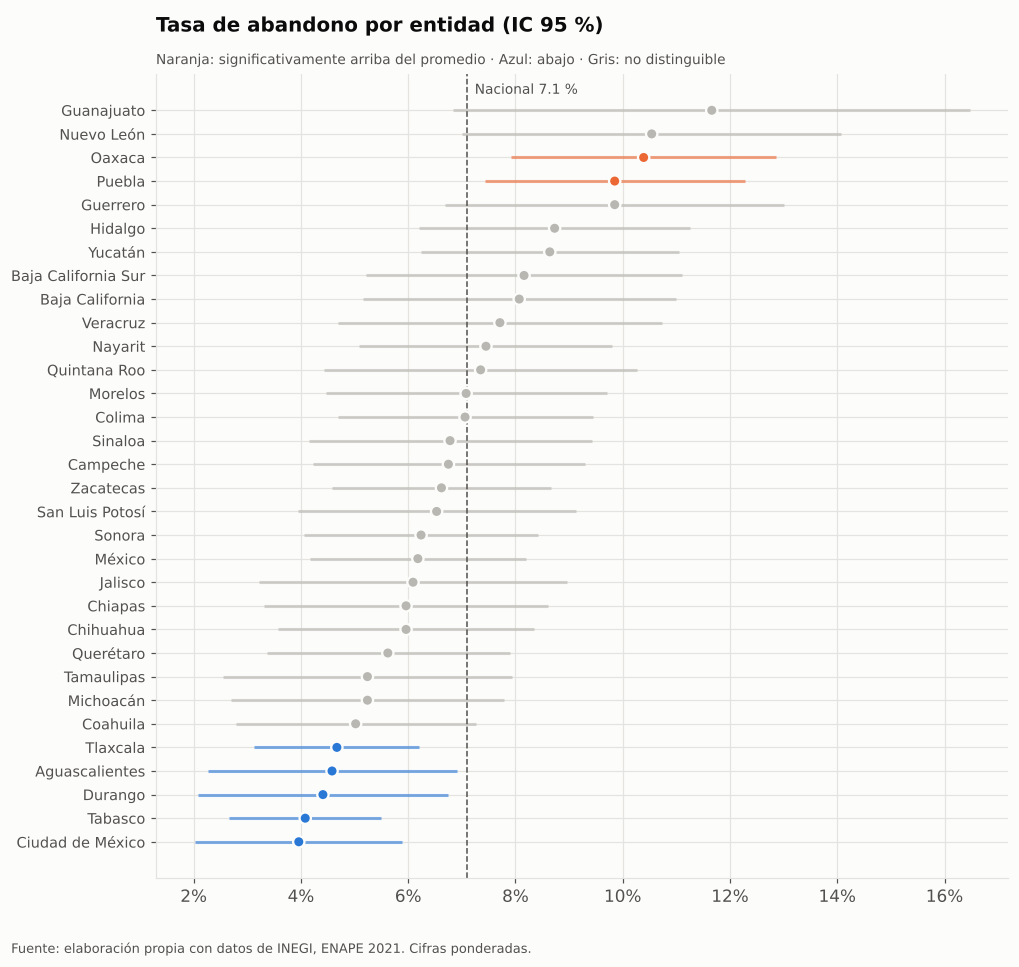

In [9]:
t_reg = tabla("region").sort_values("tasa_%")
t_cob = tabla("sin_cobertura_internet").rename(index={0: "Con cobertura", 1: "Sin cobertura de internet en la zona"})
t_ent = tabla("entidad").sort_values("tasa_%")
display(t_reg, t_cob)

fig, ax = plt.subplots(figsize=(10, 9.5))
y = np.arange(len(t_ent))
media = total["tasa_%"]
col = [C["Mujer"] if r.ic_inf > media else (C["Hombre"] if r.ic_sup < media else C["neutro"]) for _, r in t_ent.iterrows()]
ax.hlines(y, t_ent.ic_inf, t_ent.ic_sup, color=col, lw=2, alpha=0.6)
ax.scatter(t_ent["tasa_%"], y, color=col, s=55, zorder=3, edgecolor=C["fondo"], linewidth=1.5)
ax.axvline(media, color=C["tinta2"], lw=1, ls="--")
ax.text(media + 0.15, len(t_ent) - 0.3, f"Nacional {media:.1f} %", fontsize=9, color=C["tinta2"])
ax.set_yticks(y, t_ent.index, fontsize=9.5); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Tasa de abandono por entidad (IC 95 %)\n", linespacing=1.6)
ax.text(0, 1.012, "Naranja: significativamente arriba del promedio · Azul: abajo · Gris: no distinguible",
        transform=ax.transAxes, fontsize=9, color=C["tinta2"])
guardar(fig, "04_abandono_entidad")

**Hallazgo:** la región explica poco (6.6 % Centro vs 7.7 % Sur-Sureste). Por entidad, **Oaxaca (10.4 %) y Puebla (9.9 %)** están significativamente por encima del promedio, y **CDMX (4.0 %), Tabasco, Durango, Aguascalientes y Tlaxcala** por debajo. Guanajuato (11.7 %) y Nuevo León (10.5 %) tienen las tasas puntuales más altas, pero su intervalo cruza el promedio: es una señal para vigilar, no una conclusión. En hogares sin cobertura de internet el abandono sube a 10 %.

*Precaución:* cada entidad tiene ≈ 400-800 casos, por eso los intervalos son amplios; solo se interpretan las entidades cuyo intervalo no cruza el promedio.

## 6. Factor 3 · Entorno familiar (proxy de escolaridad de los padres)
La ENAPE no pregunta la escolaridad de los padres. Lo más cercano es saber **quién responde**: si es la madre/padre (convive con la persona y la sigue) u otro familiar, o la propia persona. Como quien responde por sí mismo suele ser mayor, este factor se interpreta **controlando por edad** en el modelo.

In [10]:
display(tabla("informante_padre_madre"), tabla(["grupo_edad", "informante_padre_madre"]).loc[:, ["tasa_%", "casos_muestra"]],
        tabla("tam_hogar_grupo"))

,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
informante_padre_madre,,,,,,
Madre/padre,5.58,4.95,6.21,12281.0,20.09,1.12
Otro familiar o la persona,10.18,8.93,11.42,5926.0,9.85,1.00


tasa_%  casos_muestra
grupo_edad         informante_padre_madre                           
12-14 (secundaria) Madre/padre                   2.96         2695.0
                   Otro familiar o la persona    4.95          965.0
15-17 (media sup.) Madre/padre                  10.90         2333.0
                   Otro familiar o la persona   15.99          989.0
18-22 (superior)   Madre/padre                  18.55         1898.0
                   Otro familiar o la persona   20.50         1754.0
23-29              Madre/padre                   7.20          367.0
                   Otro familiar o la persona   12.68          504.0
6-11 (primaria)    Madre/padre                   0.97         4988.0
                   Otro familiar o la persona    1.49         1714.0

,tasa_%,ic_inf,ic_sup,casos_muestra,poblacion_millones,abandonos_millones
tam_hogar_grupo,,,,,,
1-3 personas,8.83,7.29,10.37,2537.0,3.78,0.33
4-5 personas,5.44,4.80,6.08,9982.0,14.63,0.80
6 o más,8.61,7.38,9.85,5688.0,11.53,0.99


## 7. Modelo multivariado: ¿qué factores pesan *manteniendo lo demás constante*?
Regresión logística ponderada (estimada por IRLS, errores estándar robustos tipo sándwich). Variable dependiente: `abandono_reciente`. Categorías de referencia: hombre, nivel socioeconómico alto, región Centro, 6-11 años, informante madre/padre, hogar de 4-5 personas, con cobertura de internet.

In [11]:
X = pd.get_dummies(ab[["sexo", "nse_tic", "region", "grupo_edad", "informante_padre_madre", "tam_hogar_grupo"]].astype(str))
ref = ["sexo_Hombre", "nse_tic_Alto (5-6)", "region_Centro", "grupo_edad_6-11 (primaria)",
       "informante_padre_madre_Madre/padre", "tam_hogar_grupo_4-5 personas"]
X = X.drop(columns=ref).astype(float)
X["sin_cobertura_internet"] = ab["sin_cobertura_internet"].astype(float)
X.insert(0, "const", 1.0)
yv, w = ab["abandono_reciente"].values, ab["factor"].values
w = w / w.mean()                       # pesos normalizados (suman n)
Xm = X.values
beta = np.zeros(Xm.shape[1])
for _ in range(50):                    # IRLS
    p = 1 / (1 + np.exp(-Xm @ beta))
    H = Xm.T @ (Xm * (w * p * (1 - p))[:, None])
    paso = np.linalg.solve(H, Xm.T @ (w * (yv - p)))
    beta += paso
    if np.abs(paso).max() < 1e-10: break
p = 1 / (1 + np.exp(-Xm @ beta))
Hinv = np.linalg.inv(Xm.T @ (Xm * (w * p * (1 - p))[:, None]))
meat = Xm.T @ (Xm * ((w * (yv - p)) ** 2)[:, None])
se = np.sqrt(np.diag(Hinv @ meat @ Hinv))
from scipy.stats import norm
modelo = pd.DataFrame({"coef": beta, "ee_robusto": se, "odds_ratio": np.exp(beta),
                       "or_ic_inf": np.exp(beta - 1.96 * se), "or_ic_sup": np.exp(beta + 1.96 * se),
                       "p_valor": 2 * (1 - norm.cdf(np.abs(beta / se)))}, index=X.columns).round(3)
modelo

,coef,ee_robusto,odds_ratio,or_ic_inf,or_ic_sup,p_valor
const,-6.247,0.255,0.002,0.001,0.003,0.000
sexo_Mujer,-0.184,0.099,0.832,0.684,1.011,0.064
nse_tic_Bajo (0-2 bienes),1.900,0.151,6.686,4.975,8.985,0.000
nse_tic_Medio (3-4),0.777,0.134,2.174,1.672,2.827,0.000
region_Centro-Occidente,0.246,0.151,1.279,0.952,1.720,0.102
region_Norte,0.214,0.139,1.238,0.943,1.626,0.125
region_Sur-Sureste,0.201,0.141,1.222,0.927,1.612,0.155
grupo_edad_12-14 (secundaria),1.269,0.241,3.559,2.219,5.707,0.000
grupo_edad_15-17 (media sup.),2.785,0.218,16.192,10.563,24.821,0.000
grupo_edad_18-22 (superior),3.617,0.216,37.241,24.410,56.817,0.000


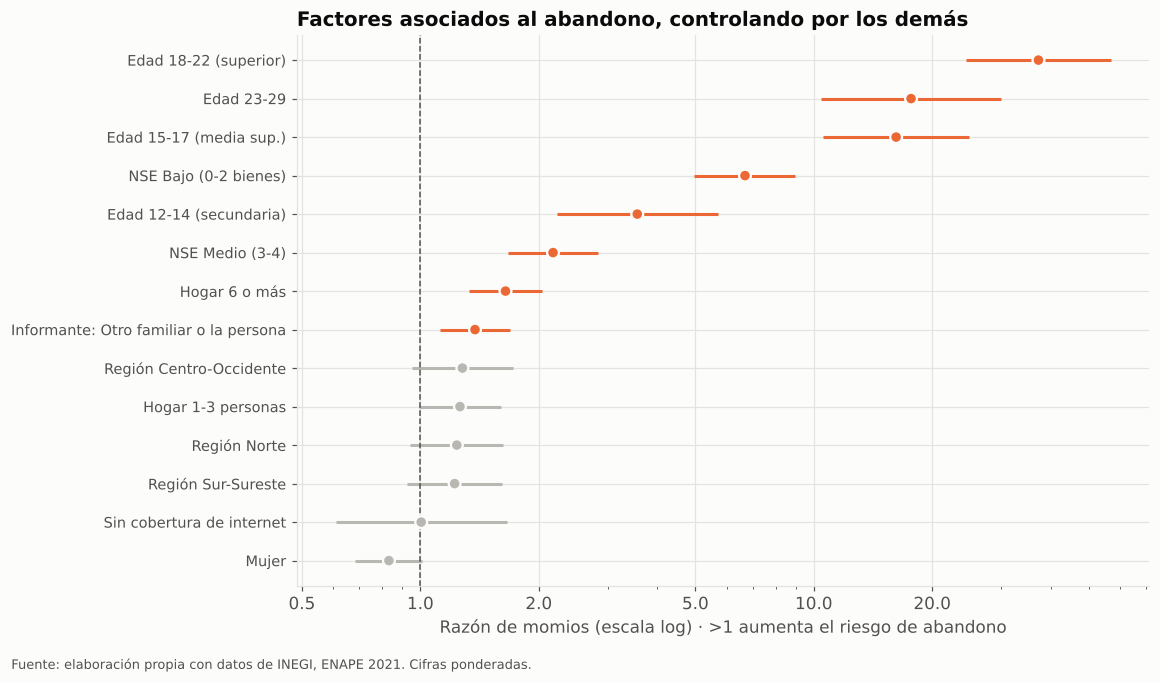

,odds_ratio,or_ic_inf,or_ic_sup,p_valor
Mujer,0.832,0.684,1.011,0.064
Sin cobertura de internet,1.005,0.609,1.659,0.985
Región Sur-Sureste,1.222,0.927,1.612,0.155
Región Norte,1.238,0.943,1.626,0.125
Hogar 1-3 personas,1.261,0.991,1.604,0.059
Región Centro-Occidente,1.279,0.952,1.720,0.102
Informante: Otro familiar o la persona,1.377,1.121,1.693,0.002
Hogar 6 o más,1.646,1.332,2.033,0.000
NSE Medio (3-4),2.174,1.672,2.827,0.000
Edad 12-14 (secundaria),3.559,2.219,5.707,0.000


In [12]:
m = modelo.drop("const").copy()
nombres = {c: c.replace("grupo_edad_", "Edad ").replace("nse_tic_", "NSE ").replace("region_", "Región ")
           .replace("sexo_", "").replace("informante_padre_madre_", "Informante: ").replace("tam_hogar_grupo_", "Hogar ")
           .replace("sin_cobertura_internet", "Sin cobertura de internet") for c in m.index}
m.index = [nombres[c] for c in m.index]
m = m.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(m))
sig = m.p_valor < 0.05
col = np.where(sig, np.where(m.odds_ratio > 1, C["Mujer"], C["Hombre"]), C["neutro"])
ax.hlines(y, m.or_ic_inf, m.or_ic_sup, color=col, lw=2)
ax.scatter(m.odds_ratio, y, color=col, s=60, zorder=3, edgecolor=C["fondo"], linewidth=1.5)
ax.axvline(1, color=C["tinta2"], lw=1, ls="--")
ax.set_xscale("log"); ax.set_xticks([0.5, 1, 2, 5, 10, 20]); ax.get_xaxis().set_major_formatter(mtick.ScalarFormatter())
ax.set_yticks(y, m.index, fontsize=9.5)
ax.set_xlabel("Razón de momios (escala log) · >1 aumenta el riesgo de abandono")
ax.set_title("Factores asociados al abandono, controlando por los demás")
guardar(fig, "05_modelo_logit")
m[["odds_ratio", "or_ic_inf", "or_ic_sup", "p_valor"]]

**Lectura del modelo:**
- **Nivel socioeconómico:** manteniendo edad, sexo, región y entorno familiar constantes, un hogar de nivel **bajo** tiene ≈ **6.7 veces** los momios de abandono de uno de nivel alto (IC 95 % en la tabla); el nivel medio, ≈ 2.2 veces. El efecto **crece** al controlar por edad: no es un artefacto de que los más pobres sean mayores.
- **Edad/etapa:** es el factor más fuerte (18-22 años ≈ 37 veces los momios de primaria; 15-17 ≈ 16 veces).
- **Entorno familiar:** cuando quien responde no es la madre/padre, los momios suben ≈ 38 % aun a igual edad; y en hogares de 6 o más personas ≈ 65 % (más dependientes compitiendo por los mismos recursos).
- **Sexo, región y cobertura de internet:** no son significativos (p > 0.05) una vez que se controla lo demás. El 10 % de abandono en zonas sin cobertura se explica por su menor nivel socioeconómico. El sexo no cambia *cuánto* se abandona, sino *por qué* (sección 8).

*Es un modelo de asociación, no causal:* no hay variación exógena que permita aislar causas.

## 8. Razones del abandono por sexo

sexo,Hombre,Mujer
razon_no_inscripcion_2021_22,,
Falta de dinero o recursos,29.0,29.2
Falta de interés o aptitud,21.2,15.7
Pandemia COVID-19,13.9,15.4
Otra razón,11.4,10.5
Tenía que trabajar,8.9,7.4
Problemas personales,4.0,5.0
No hay escuela cercana,3.9,4.7
Reprobó materias / bajo rendimiento,3.9,3.9


sexo,Hombre,Mujer
razon_dejo_escuela,,
Falta de dinero o recursos,25.0,28.9
Falta de interés o aptitud,29.9,19.7
Tenía que trabajar,29.2,15.5
"Se unió, casó o embarazo",6.1,21.6
Otra razón,1.7,2.4
Problemas personales,2.2,1.8
Quehaceres del hogar o cuidados,0.1,3.5
Reprobó materias / bajo rendimiento,1.7,1.0


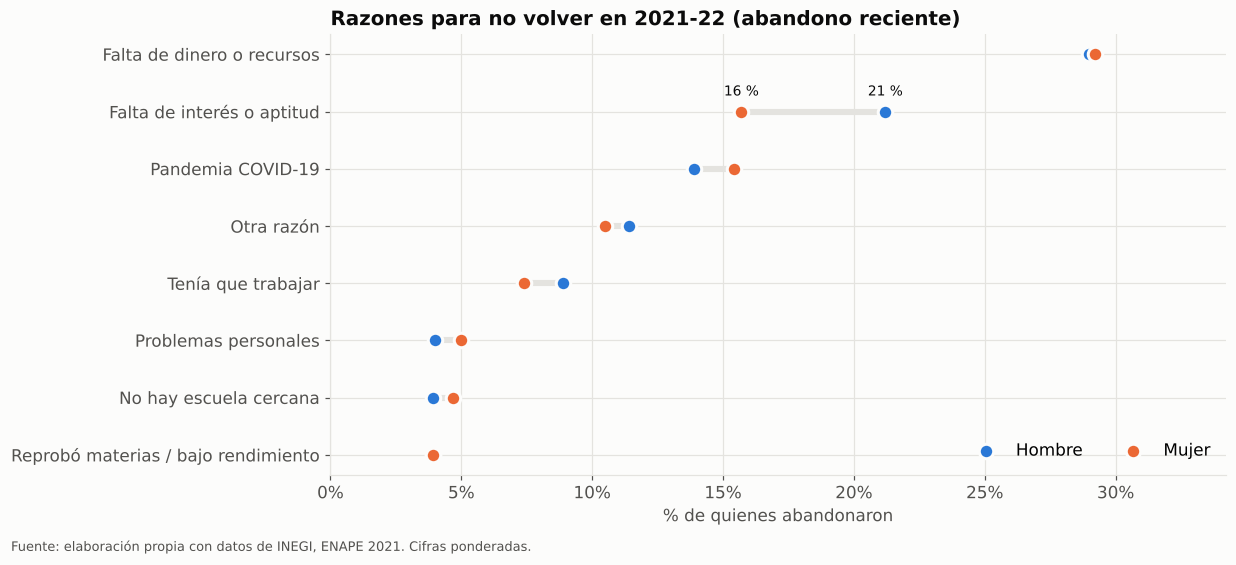

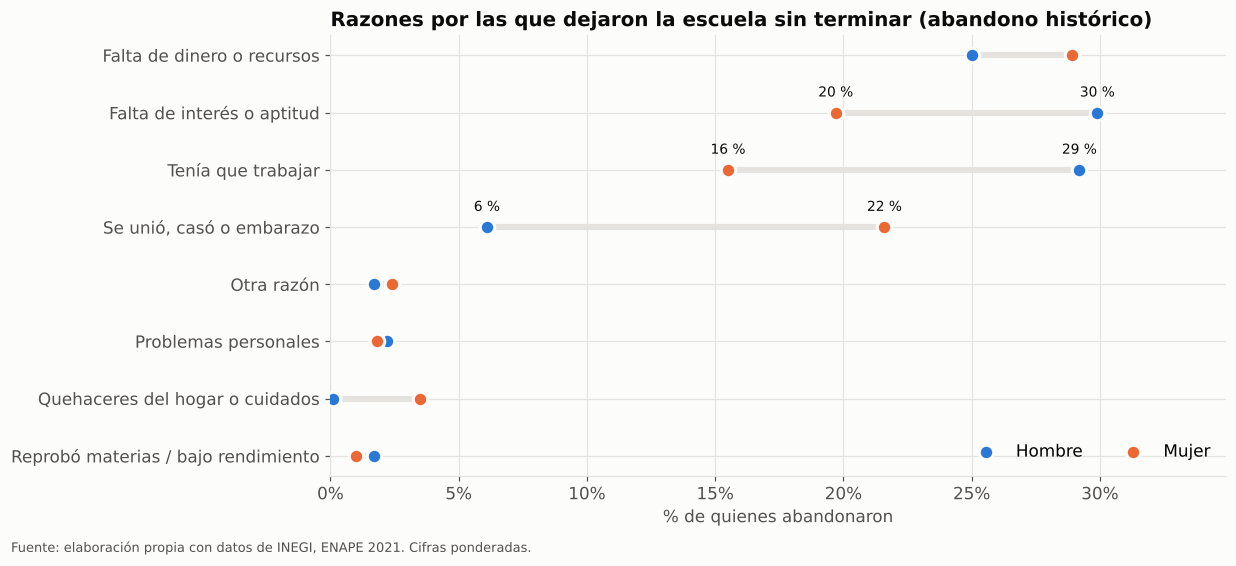

In [13]:
def razones(sub, col, top=8):
    t = sub.groupby(["sexo", col]).factor.sum().unstack(0)
    t = t / t.sum() * 100
    return t.loc[t.mean(axis=1).sort_values(ascending=False).index].head(top).round(1)

r_rec = razones(d[d.abandono_reciente == 1], "razon_no_inscripcion_2021_22")
r_his = razones(d[d.abandono_historico == 1], "razon_dejo_escuela")
display(r_rec, r_his)

def dumbbell(t, titulo, nombre):
    t = t.iloc[::-1]
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    y = np.arange(len(t))
    ax.hlines(y, t.min(axis=1), t.max(axis=1), color=C["grid"], lw=4)
    for s in ["Hombre", "Mujer"]:
        ax.scatter(t[s], y, color=C[s], s=90, zorder=3, label=s, edgecolor=C["fondo"], linewidth=2)
    for i, (h, mu) in enumerate(zip(t["Hombre"], t["Mujer"])):
        if abs(h - mu) >= 4:
            for v, s in [(h, "Hombre"), (mu, "Mujer")]:
                ax.text(v, i + 0.28, f"{v:.0f} %", ha="center", fontsize=9, color=C["tinta"])
    ax.set_yticks(y, t.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_xlim(0, t.values.max() + 5); ax.set_xlabel("% de quienes abandonaron")
    ax.set_title(titulo); ax.legend(loc="lower right", ncol=2)
    guardar(fig, nombre)

dumbbell(r_rec, "Razones para no volver en 2021-22 (abandono reciente)", "06_razones_recientes_sexo")
dumbbell(r_his, "Razones por las que dejaron la escuela sin terminar (abandono histórico)", "07_razones_historicas_sexo")

**Hallazgos (H3 se confirma en el abandono histórico):**
- **La razón número uno para ambos sexos es económica:** falta de dinero o recursos (29 % en el abandono reciente para hombres y mujeres).
- **Hombres → mercado laboral y desinterés:** *tenía que trabajar* es 29 % de los hombres vs 16 % de las mujeres, y *falta de interés* 30 % vs 20 % (en el abandono reciente, 21 % vs 16 %).
- **Mujeres → unión, embarazo y cuidados:** *se unió, casó o embarazo* es **22 % de las mujeres vs 6 % de los hombres**; *quehaceres del hogar o cuidados* casi solo aparece en mujeres. Son razones que el resto del análisis no captaría sin una perspectiva de género.
- **La pandemia** pesó en el ciclo 2021-22 (14-15 %), pero sigue detrás del dinero y la falta de interés.

## 9. Abandono, dinero y trabajo

,% razones económicas (dinero o trabajo)
nse_tic,
Bajo (0-2 bienes),45.4
Medio (3-4),34.9
Alto (5-6),16.2


,Continuó estudiando,Abandonó
sexo,,
Hombre,29.7,67.8
Mujer,21.5,45.2


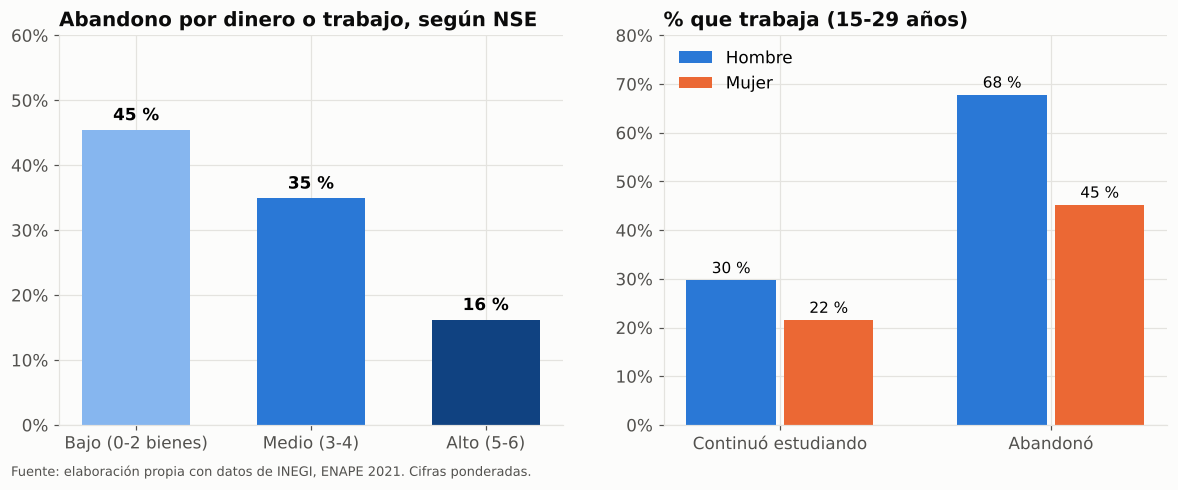

In [14]:
din = ab[ab.abandono_reciente == 1].groupby("nse_tic", observed=True).apply(lambda s: np.average(
    s.razon_no_inscripcion_2021_22.isin(["Falta de dinero o recursos", "Tenía que trabajar"]), weights=s.factor) * 100
).reindex(NSE_ORD)
tr = ab[(ab.edad >= 15) & ab.trabaja.notna()].copy()
tr_tab = tr.groupby(["sexo", "abandono_reciente"]).apply(lambda s: np.average(s.trabaja, weights=s.factor) * 100).unstack()
tr_tab.columns = ["Continuó estudiando", "Abandonó"]
display(din.round(1).to_frame("% razones económicas (dinero o trabajo)"), tr_tab.round(1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
a1.bar(range(3), din.values, color=[AZUL[k] for k in NSE_ORD], width=0.62)
for i, v in enumerate(din.values): a1.text(i, v + 1.5, f"{v:.0f} %", ha="center", fontweight="bold")
a1.set_xticks(range(3), NSE_ORD); a1.set_ylim(0, 60); a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a1.set_title("Abandono por dinero o trabajo, según NSE")
x = np.arange(2); wd = 0.36
for k, s in enumerate(["Hombre", "Mujer"]):
    a2.bar(x + (k - 0.5) * wd, tr_tab.loc[s].values, wd - 0.03, color=C[s], label=s)
    for i, v in enumerate(tr_tab.loc[s].values): a2.text(i + (k - 0.5) * wd, v + 1.5, f"{v:.0f} %", ha="center", fontsize=10)
a2.set_xticks(x, tr_tab.columns); a2.set_ylim(0, 80); a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.set_title("% que trabaja (15-29 años)"); a2.legend()
guardar(fig, "08_dinero_trabajo")

**Hallazgo:** entre quienes abandonaron, el motivo es económico (dinero o trabajo) en **45 %** de los casos de hogares de nivel bajo contra **16 %** en nivel alto. Entre los jóvenes de 15-29 años que abandonaron, **68 % de los hombres y 45 % de las mujeres ya trabaja**, contra 30 % y 22 % de quienes siguieron estudiando: el costo de oportunidad de estudiar es la palanca central, y pesa más en los hombres.

## 10. ¿Quieren volver?

In [15]:
ret = d[d.piensa_retomar.notna()]
ret_sexo = ret.groupby("sexo").apply(lambda s: np.average(s.piensa_retomar == "Sí", weights=s.factor) * 100)
ret_raz = ret[ret.razon_dejo_escuela.isin(r_his.index[:5])].groupby("razon_dejo_escuela").apply(
    lambda s: np.average(s.piensa_retomar == "Sí", weights=s.factor) * 100).sort_values()
display(ret_sexo.round(1).to_frame("% piensa retomar"), ret_raz.round(1).to_frame("% piensa retomar"))

,% piensa retomar
sexo,
Hombre,25.8
Mujer,31.3


,% piensa retomar
razon_dejo_escuela,
Falta de interés o aptitud,14.4
"Se unió, casó o embarazo",21.2
Falta de dinero o recursos,23.9
Tenía que trabajar,25.6
Otra razón,59.1


**Hallazgo:** 31 % de las mujeres y 26 % de los hombres fuera de la escuela piensa retomar sus estudios. Hay demanda latente, sobre todo entre mujeres, que una oferta flexible (abierta, en línea, con horarios compatibles con cuidados) podría captar.

## 11. Síntesis, recomendaciones y limitaciones

**Respuesta a la pregunta:**
1. **Ingreso (proxy TIC):** factor socioeconómico más fuerte. Abandono de 10.4 % en NSE bajo vs 3.8 % en alto; ≈ 6.7× los momios aun controlando edad, sexo, región y familia. En media superior la brecha llega a 34 % vs 12 %.
2. **Entorno familiar (proxy de padres):** cuando la madre/padre no es quien responde, los momios suben ≈ 38 % a igual edad; hogares de 6+ personas, ≈ 65 %.
3. **Zona:** la región no es significativa; las diferencias están por entidad (Oaxaca y Puebla significativamente arriba; CDMX abajo). La mayor tasa en zonas sin cobertura de internet (10 %) se explica por su menor ingreso.
4. **Razones por sexo:** la falta de dinero encabeza para ambos; los hombres salen hacia el **trabajo**, las mujeres por **unión/embarazo y cuidados**.

**Recomendaciones accionables:**
- **Focalizar becas en la transición secundaria → media superior** de hogares de nivel bajo (donde 1 de cada 3 abandona) y condicionarlas a permanencia, no solo a inscripción.
- **Compensar el costo de oportunidad:** programas de estudio-trabajo y horarios compatibles en bachillerato (68 % de los hombres que abandonan ya trabaja). Oportunidad para empresas: alianzas de formación dual que no obliguen a elegir entre empleo y escuela.
- **Enfoque de género:** estancias infantiles en planteles, prevención del embarazo adolescente y flexibilidad para madres estudiantes.
- **Conectividad:** cerrar la brecha de internet en zonas sin cobertura.
- **Reincorporación:** aprovechar que ≈ 3 de cada 10 quieren volver con oferta abierta y en línea.

**Limitaciones:** encuesta telefónica (subrepresenta hogares sin teléfono, probablemente los más pobres → las brechas reales serían mayores); sin ingreso, escolaridad de los padres ni urbano/rural (se usan proxies); razones reportadas por un informante; ciclo afectado por la pandemia; asociación, no causalidad; IC aproximados sin diseño muestral completo.

## 12. Reporte estadístico de la base final
Genera `Reporte_Estadistico.html`: perfil de cada variable de la base final (tipo, faltantes, descriptivos ponderados, distribución de categorías) y las tablas principales.

In [16]:
import html as _h
filas_html = []
for c in d.columns:
    s = d[c]
    falt = s.isna().mean() * 100
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 2 and c not in ["factor"]:
        ok = s.notna()
        x, wv = s[ok].astype(float), d.loc[ok, "factor"]
        det = (f"media pond. {wmedia(x, wv):.2f} · mediana pond. {wmediana(x, wv):.0f} · d.e. {wsd(x, wv):.2f} · "
               f"mín {x.min():.0f} · máx {x.max():.0f}")
    elif c in ["folio", "renglon", "factor"]:
        det = f"{s.nunique():,} valores únicos" + (f" · suma {s.sum():,.0f}" if c == "factor" else "")
    else:
        vc = d.groupby(s.astype(str).where(s.notna(), "(vacío)")).factor.sum()
        vc = (vc / vc.sum() * 100).sort_values(ascending=False).head(6)
        det = " · ".join(f"{_h.escape(str(k))}: {v:.1f} %" for k, v in vc.items())
    filas_html.append(f"<tr><td><code>{c}</code></td><td>{s.dtype}</td><td>{s.notna().sum():,}</td>"
                      f"<td>{falt:.1f} %</td><td>{det}</td></tr>")

def t_html(df_): return df_.to_html(classes="t", border=0, float_format=lambda v: f"{v:,.2f}")
reporte = f"""<!doctype html><html lang="es"><head><meta charset="utf-8"><title>Reporte estadístico</title>
<style>body{{font-family:system-ui,sans-serif;max-width:1100px;margin:32px auto;padding:0 16px;color:#0b0b0b;background:#fcfcfb}}
h1{{margin-bottom:4px}} .sub{{color:#52514e}} table.t,table.v{{border-collapse:collapse;width:100%;font-size:13px;margin:12px 0 28px}}
td,th{{border-bottom:1px solid #e4e3df;padding:6px 8px;text-align:left;vertical-align:top}} th{{background:#1F3A5F;color:#fff}}
code{{background:#eef2f7;padding:1px 4px;border-radius:3px}} img{{max-width:100%;margin:8px 0 24px}}</style></head><body>
<h1>Reporte estadístico · Base final ENAPE 2021 (abandono escolar)</h1>
<p class="sub">Manuel Aguirre · UDEM · Fuente: INEGI, ENAPE 2021. {len(d):,} registros (personas de 0-29 años) × {d.shape[1]} variables;
representan {d.factor.sum()/1e6:.1f} millones de personas. Estadísticos ponderados con el factor de expansión.</p>
<h2>1. Perfil de variables</h2><table class="v"><tr><th>Variable</th><th>Tipo</th><th>No vacíos</th><th>% vacío</th><th>Resumen</th></tr>
{''.join(filas_html)}</table>
<p class="sub">Los vacíos son estructurales: cada pregunta solo aplica a su subpoblación (p. ej. la razón de no inscripción solo a quien no se inscribió).</p>
<h2>2. Indicador principal</h2><p>Tasa de abandono escolar 2020-21 → 2021-22 (6-29 años inscritos en 2020-21):
<b>{total['tasa_%']:.1f} %</b> (IC 95 % {total.ic_inf:.1f}–{total.ic_sup:.1f}), {total.abandonos_millones:.2f} millones de personas.</p>
<h3>Por sexo</h3>{t_html(tabla('sexo'))}<h3>Por nivel socioeconómico (proxy TIC)</h3>{t_html(t_nse)}
<h3>Por nivel cursado × NSE (tasa %)</h3>{t_html(heat.round(1))}<h3>Por región</h3>{t_html(t_reg)}
<h2>3. Descriptivos ponderados</h2>{t_html(desc)}
<h2>4. Correlaciones ponderadas</h2>{t_html(corr)}
<h2>5. Modelo logístico ponderado</h2>{t_html(modelo)}
<h2>6. Razones por sexo (% de quienes abandonaron)</h2><h3>Abandono reciente</h3>{t_html(r_rec)}<h3>Abandono histórico</h3>{t_html(r_his)}
<h2>7. Gráficas</h2>{''.join(f'<img src="graficas/{p.name}" alt="{p.stem}">' for p in sorted(GRAF.glob('*.png')))}
</body></html>"""
Path("Reporte_Estadistico.html").write_text(reporte, encoding="utf-8")
print("Reporte_Estadistico.html generado ·", len(reporte) // 1024, "KB")

Reporte_Estadistico.html generado · 21 KB
